# Load the Dataset

In [22]:
import numpy as np
import pandas as pd

measurements = {}

for label, folder in classes.items():
    folder_path = dataset_path / folder
    measurements[label] = {}

    for file_path in sorted(folder_path.glob("*.txt")):

        df = pd.read_csv(
            file_path,
            sep="\t",
            header=None
        )

        # Remove empty columns caused by leading/trailing tabs
        df = df.dropna(axis=1, how="all")

        measurements[label][file_path.stem] = df.to_numpy(dtype=float)

print("Dataset loaded successfully!\n")

for label, samples in measurements.items():
    print(f"{label}: {len(samples)} measurements")
    print("First measurement shape:",
          next(iter(samples.values())).shape)

Dataset loaded successfully!

HQ: 20 measurements
First measurement shape: (300, 8)
AQ: 10 measurements
First measurement shape: (300, 8)
LQ: 28 measurements
First measurement shape: (300, 8)


# Let see the initial 10 values

In [23]:
for label in ["HQ", "AQ", "LQ"]:
    sample_name = selected_samples[label]
    signal = measurements[label][sample_name]

    print(f"\n{label}: {sample_name}")
    print("Shape:", signal.shape)
    print("Sensor 1 first 10 values:", signal[:10, 0])
    print("Valid values:", np.isfinite(signal[:, 0]).sum())


HQ: HQ_04
Shape: (300, 8)
Sensor 1 first 10 values: [50.568114 50.238644 49.91308  50.402887 50.238644 49.431904 49.91308
 50.075378 50.402887 49.91308 ]
Valid values: 300

AQ: AQ_01
Shape: (300, 8)
Sensor 1 first 10 values: [33.739782 33.820116 33.900787 33.900787 33.580114 33.500777 33.820116
 33.739782 34.144839 34.144839]
Valid values: 300

LQ: LQ_24
Shape: (300, 8)
Sensor 1 first 10 values: [39.660745 39.983371 40.310723 39.767768 39.875309 40.201074 39.767768
 39.875309 40.201074 39.875309]
Valid values: 300


# Plot the distribution of the classses

Class distribution:
HQ    20
AQ    10
LQ    28
Name: Measurements, dtype: int64


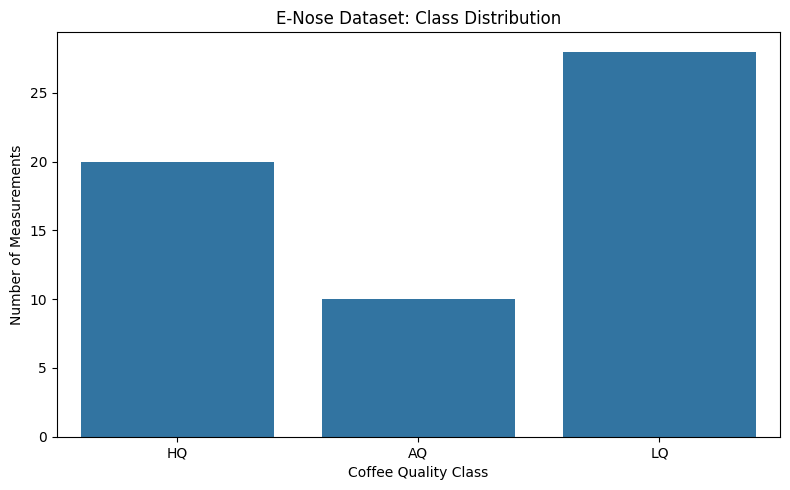

In [24]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

classes = {
    "HQ": "HQ_Coffee",
    "AQ": "AQ_Coffee",
    "LQ": "LQ_Coffee"
}

# Count measurements in each class
class_counts = {}
for label, folder in classes.items():
    folder_path = dataset_path / folder
    if folder_path.exists():
        class_counts[label] = len(list(folder_path.glob("*.txt")))
    else:
        class_counts[label] = 0

counts = pd.Series(class_counts, name="Measurements")

print("Class distribution:")
print(counts)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x=counts.index, y=counts.values)

plt.title("E-Nose Dataset: Class Distribution")
plt.xlabel("Coffee Quality Class")
plt.ylabel("Number of Measurements")
plt.tight_layout()
plt.show()

# Ploting the 8 sensor measurement taking a individual measurement of each category.

**Comparing the reading of all the three class parallely to understand the pattern while 300 second**

Selected measurements:
HQ: HQ_04
AQ: AQ_01
LQ: LQ_24


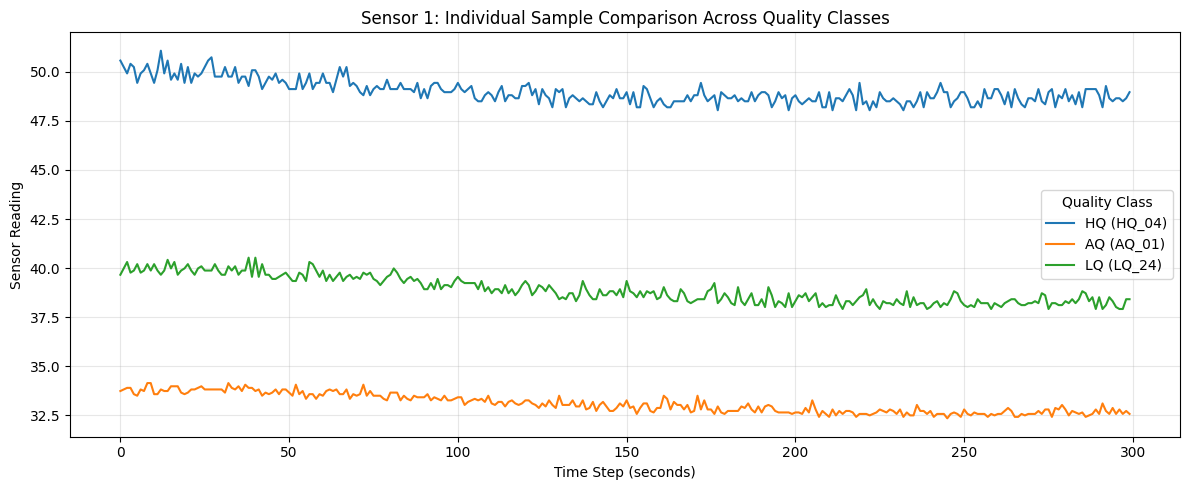

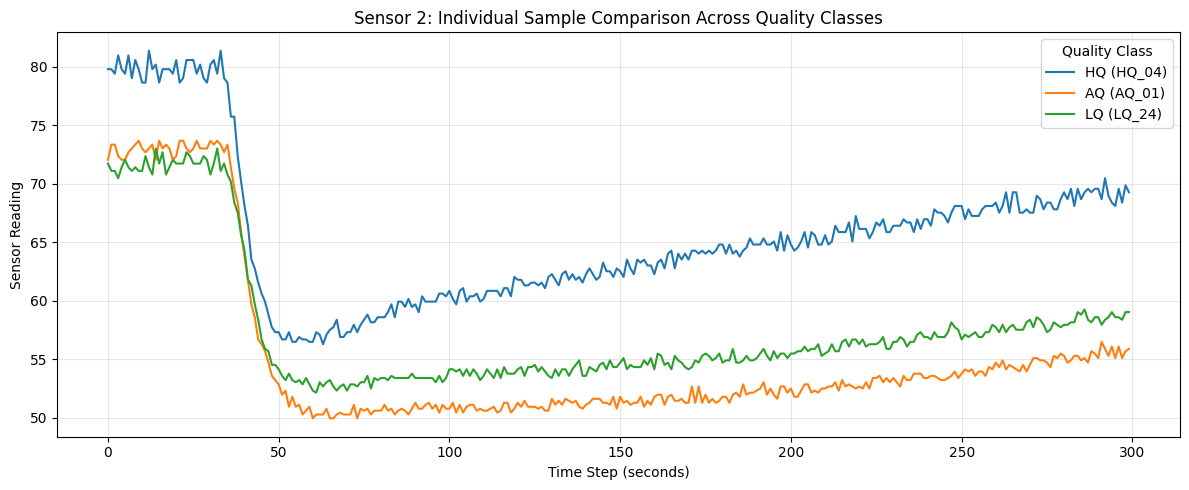

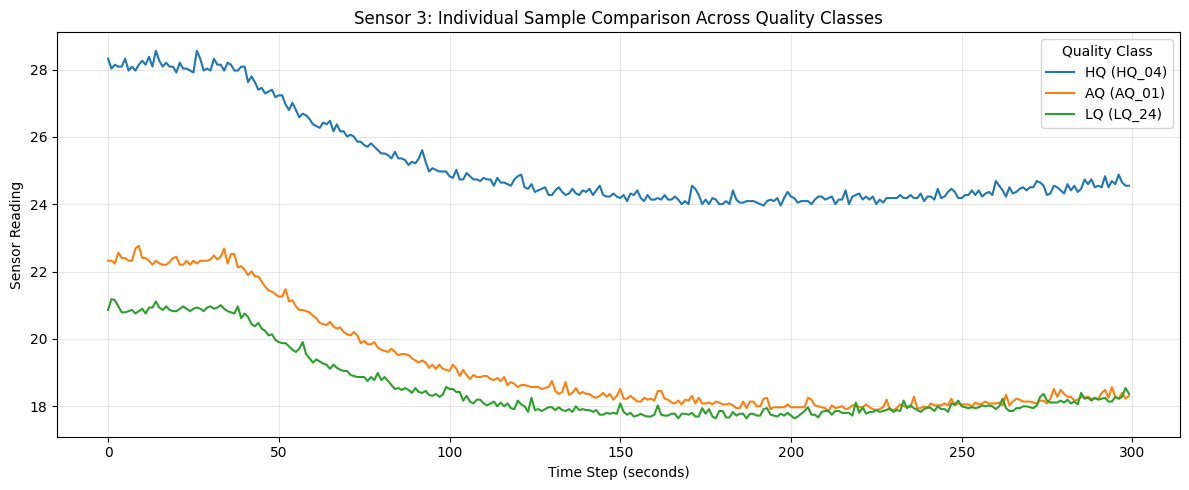

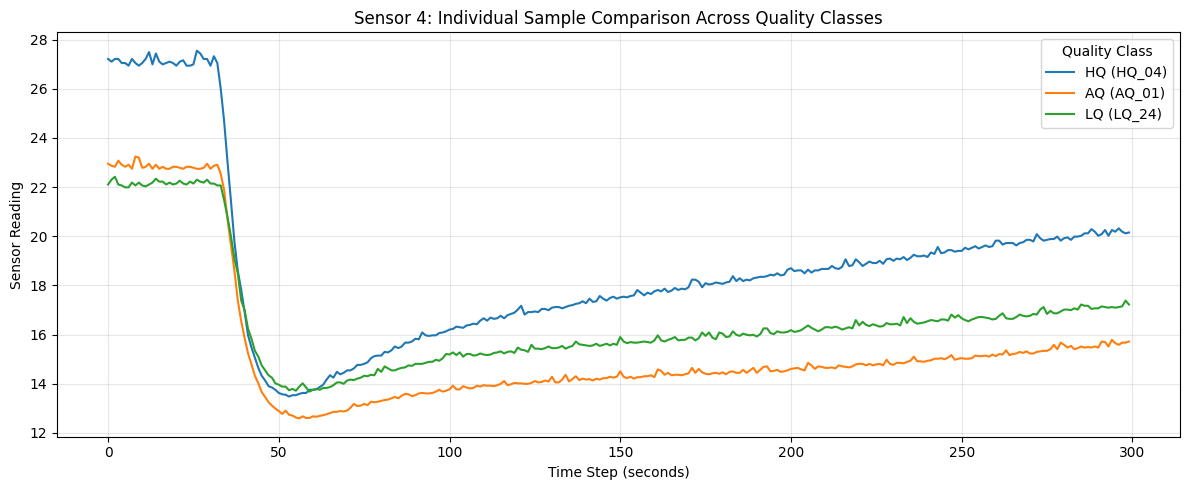

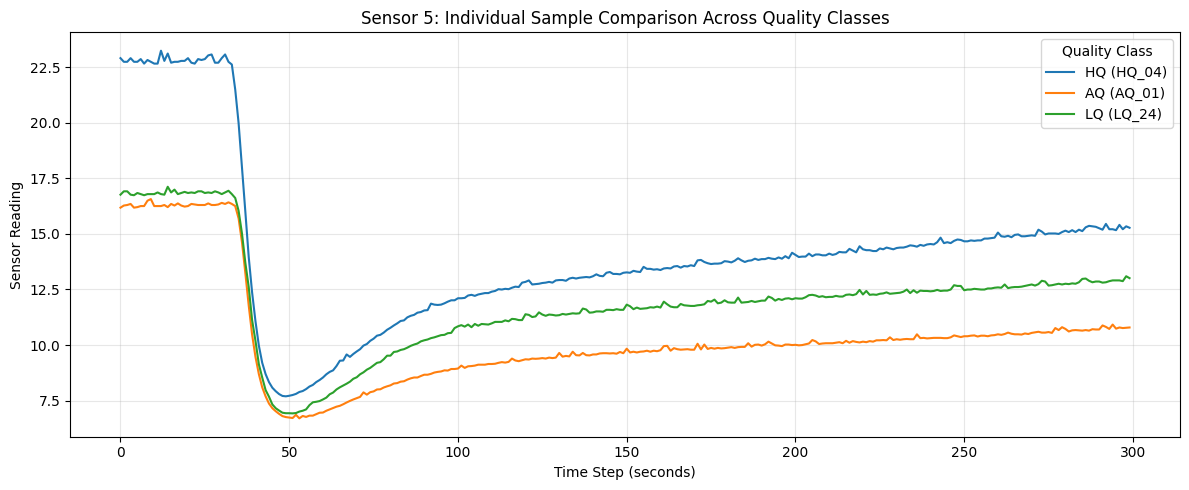

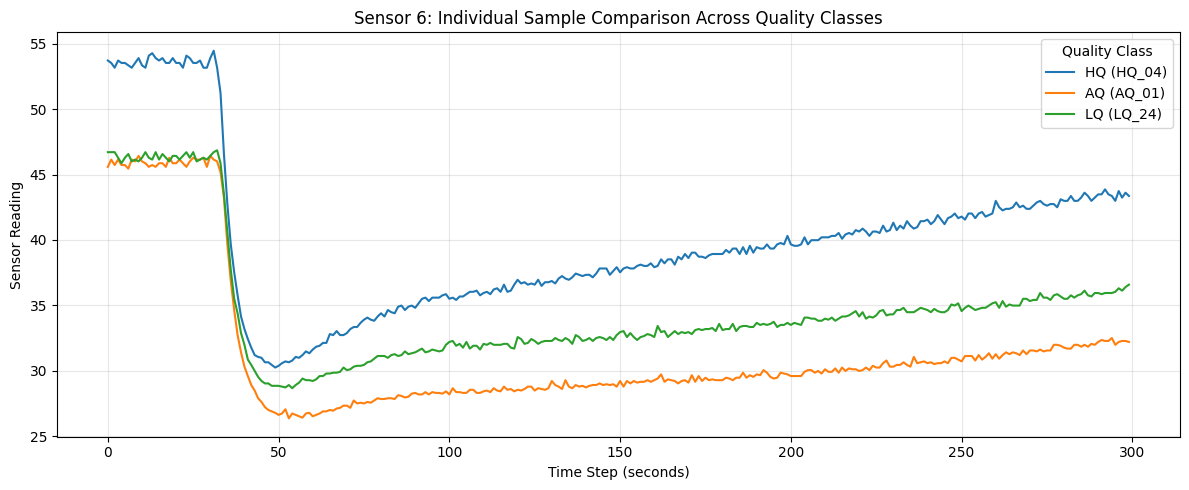

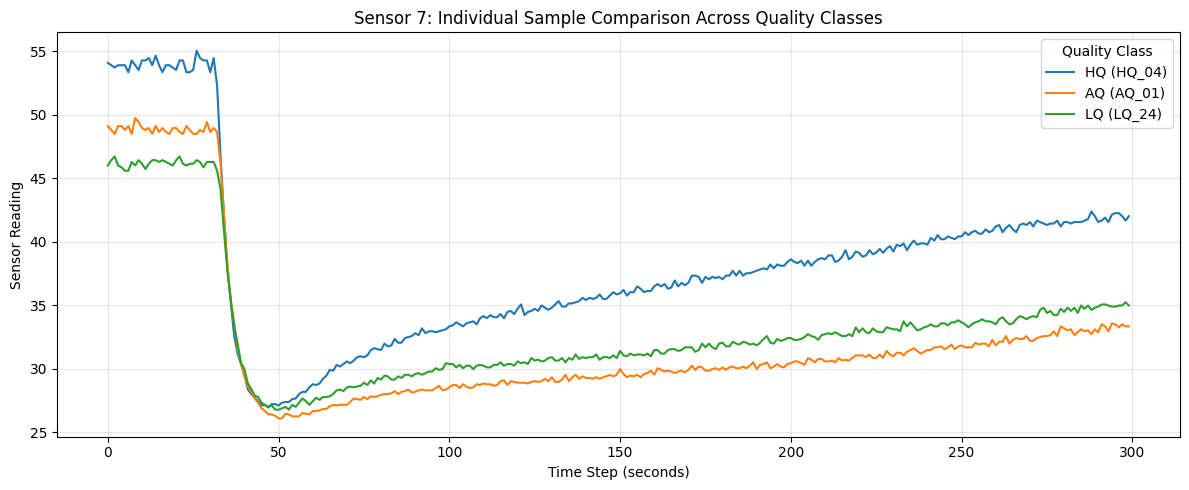

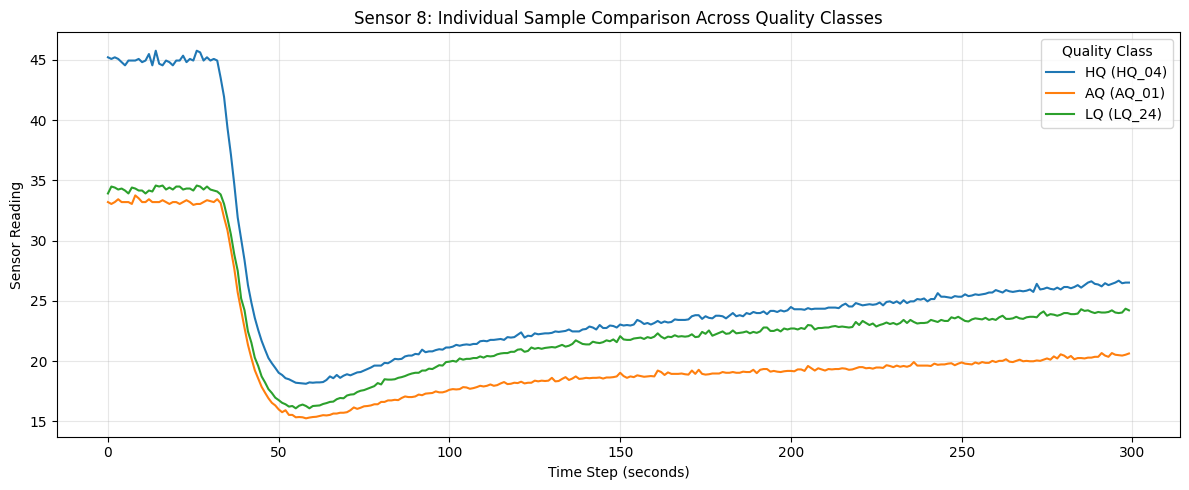

In [25]:
# Fixed seed makes the random selection reproducible
rng = random.Random(42)

selected_samples = {
    label: rng.choice(list(samples.keys()))
    for label, samples in measurements.items()
}

print("Selected measurements:")
for label, sample_name in selected_samples.items():
    print(f"{label}: {sample_name}")

time_steps = np.arange(300)

for sensor_idx in range(8):

    plt.figure(figsize=(12, 5))

    for label in ["HQ", "AQ", "LQ"]:
        sample_name = selected_samples[label]
        signal = measurements[label][sample_name][:, sensor_idx]

        plt.plot(
            time_steps,
            signal,
            label=f"{label} ({sample_name})",
            linewidth=1.5
        )

    plt.title(
        f"Sensor {sensor_idx + 1}: "
        "Individual Sample Comparison Across Quality Classes"
    )
    plt.xlabel("Time Step (seconds)")
    plt.ylabel("Sensor Reading")
    plt.legend(title="Quality Class")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [26]:
import numpy as np
import matplotlib.pyplot as plt

time_steps = np.arange(300)

# Calculate mean and standard deviation for each sensor in each class
class_statistics = {}

for label, samples in measurements.items():

    # Shape: (measurements, time steps, sensors)
    all_signals = np.stack(list(samples.values()), axis=0)

    class_statistics[label] = {
        "mean": np.mean(all_signals, axis=0),
        "std": np.std(all_signals, axis=0, ddof=1)
    }

    print(f"{label}: {all_signals.shape[0]} measurements included")

HQ: 20 measurements included
AQ: 10 measurements included
LQ: 28 measurements included


# **Plotting the time series distribution taking the Average of all the measurement**

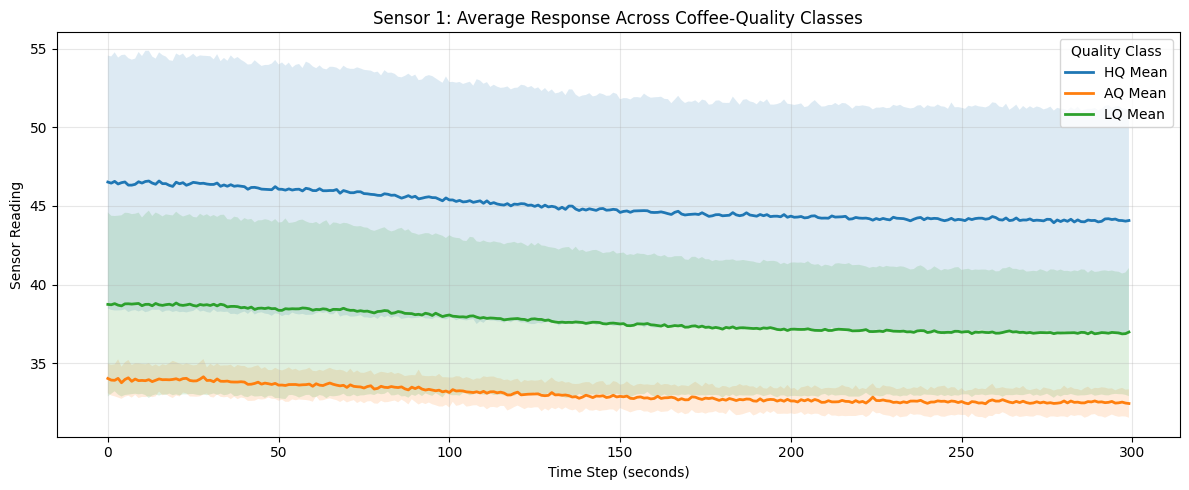

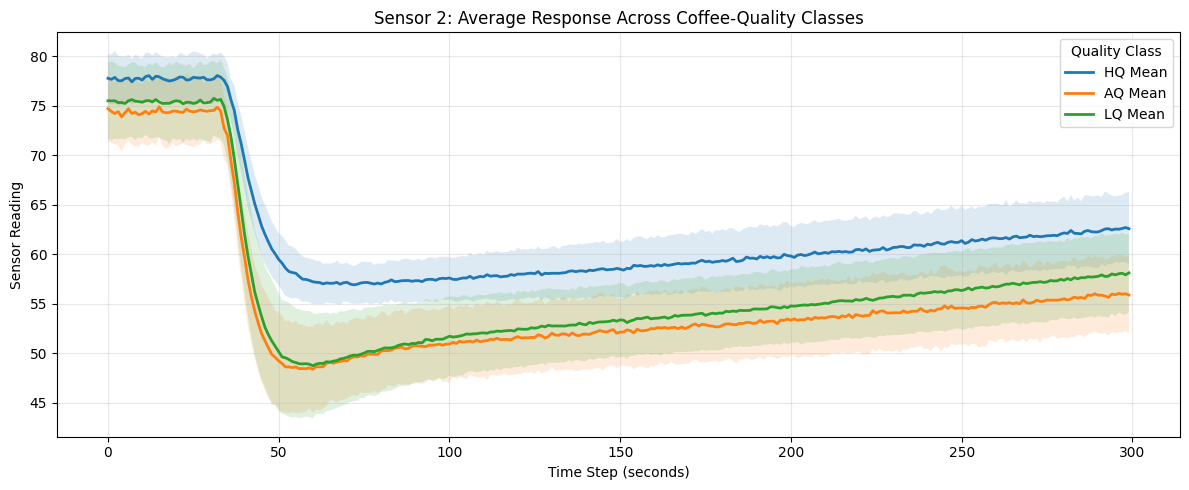

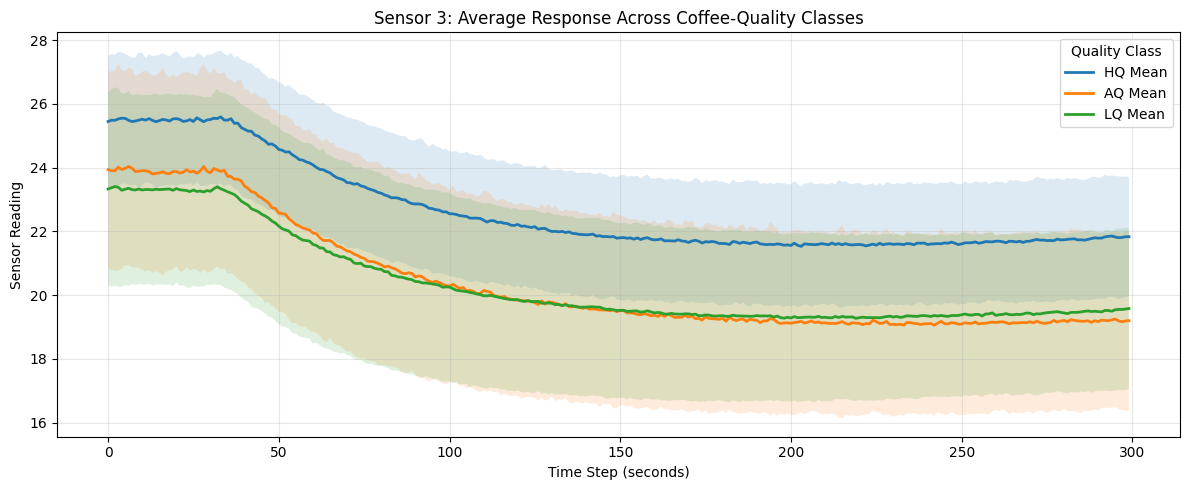

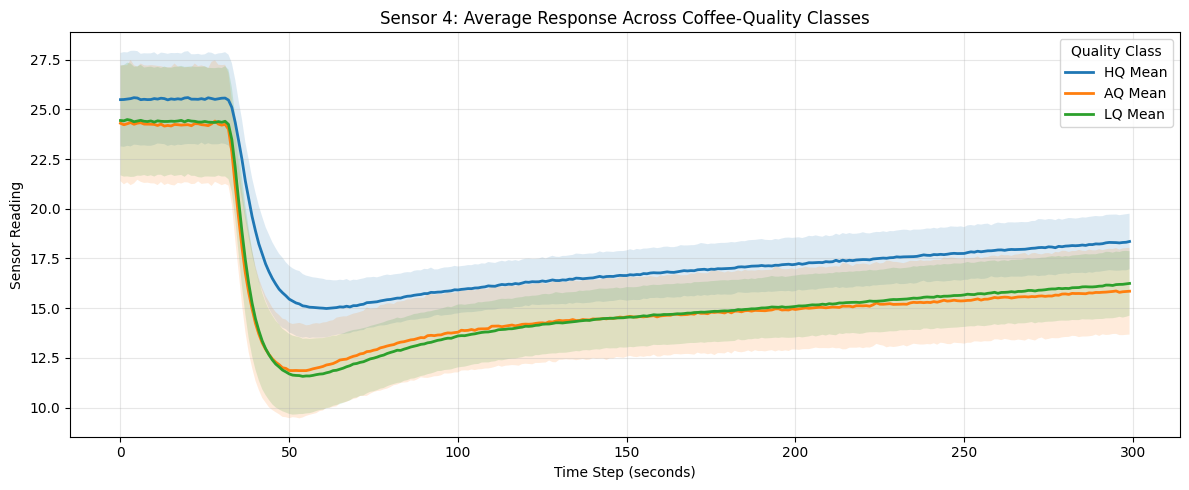

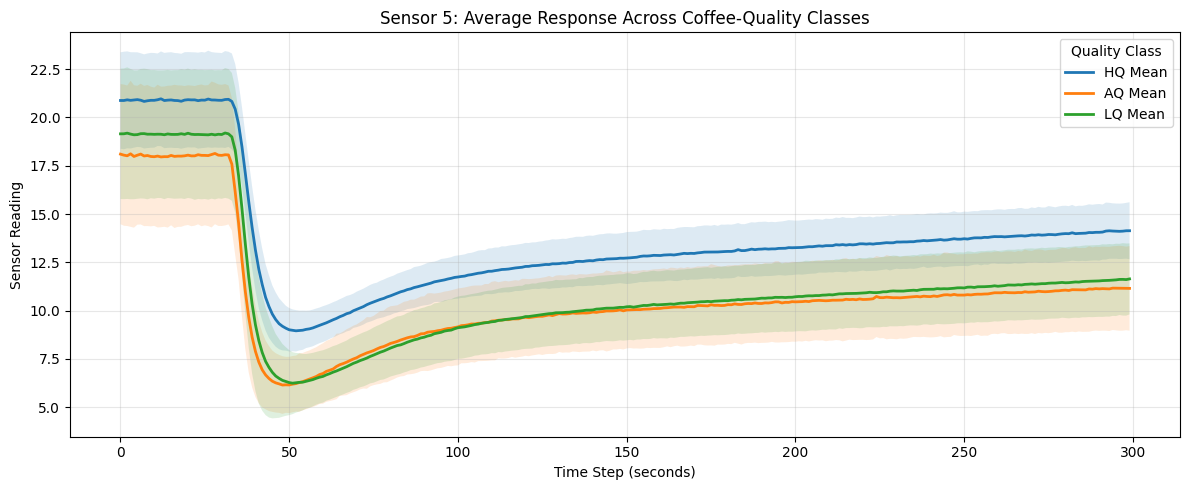

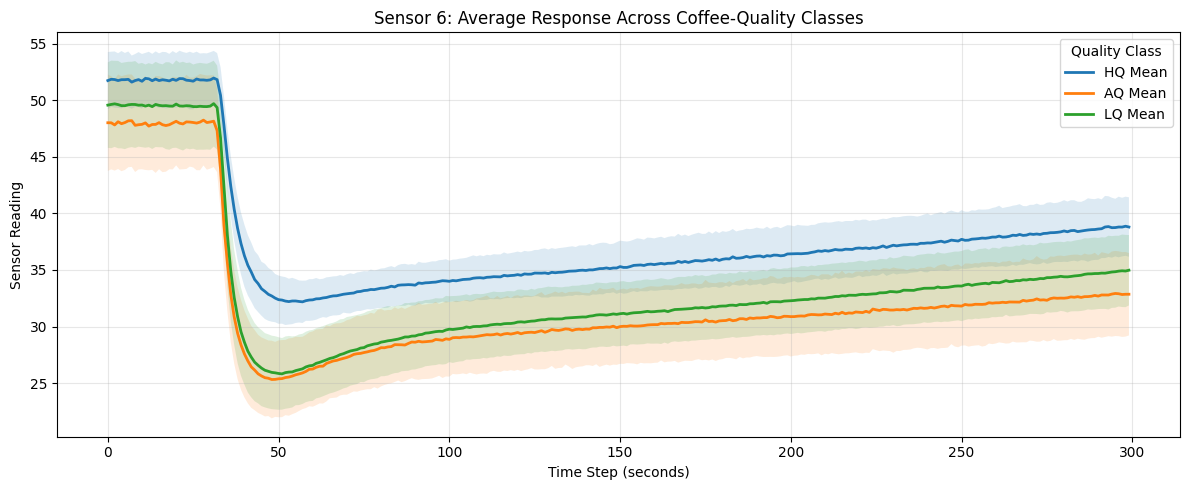

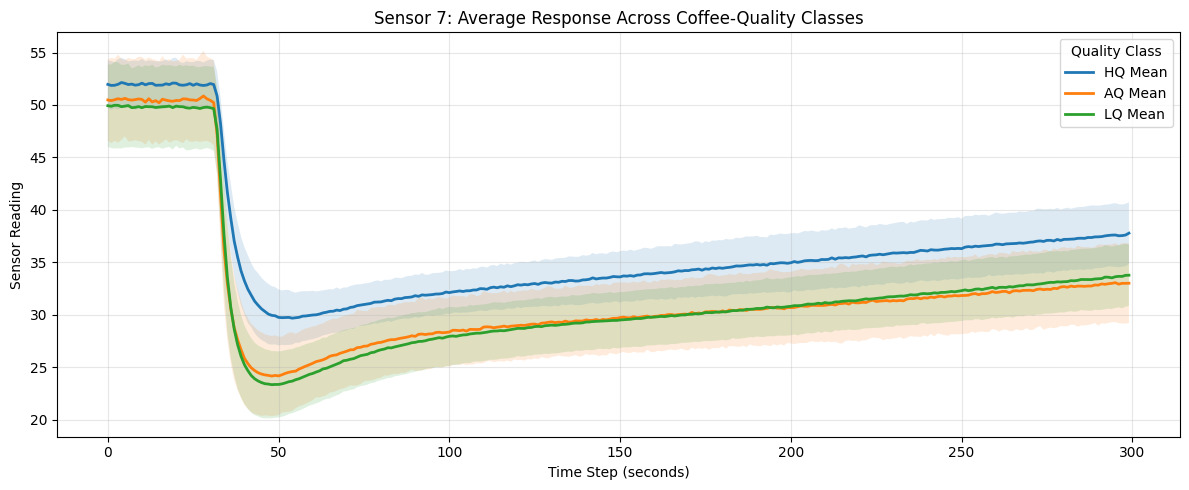

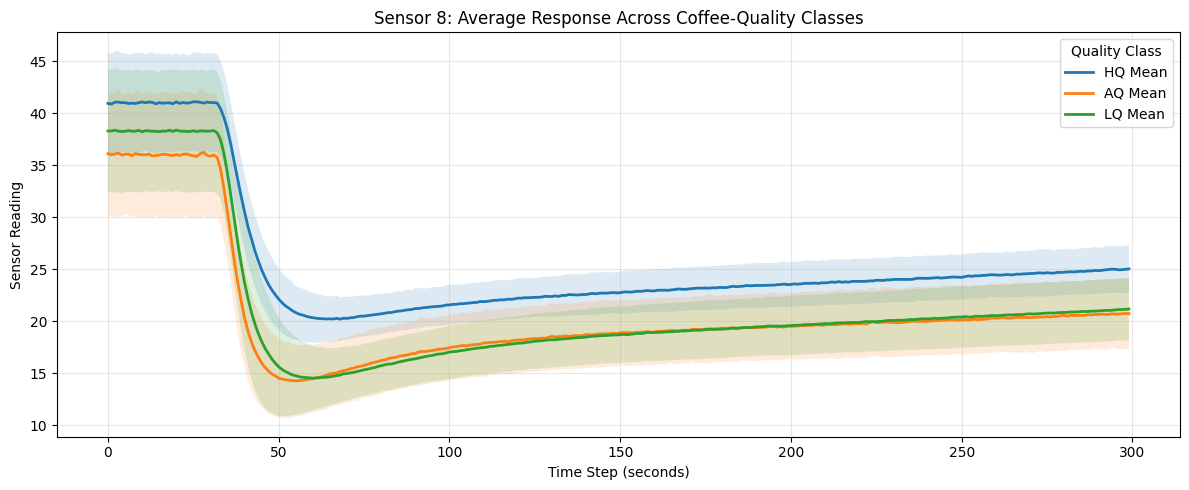

In [27]:
for sensor_idx in range(8):

    plt.figure(figsize=(12, 5))

    for label in ["HQ", "AQ", "LQ"]:

        mean_signal = class_statistics[label]["mean"][:, sensor_idx]
        std_signal = class_statistics[label]["std"][:, sensor_idx]

        plt.plot(
            time_steps,
            mean_signal,
            label=f"{label} Mean",
            linewidth=2
        )

        plt.fill_between(
            time_steps,
            mean_signal - std_signal,
            mean_signal + std_signal,
            alpha=0.15
        )

    plt.title(
        f"Sensor {sensor_idx + 1}: "
        "Average Response Across Coffee-Quality Classes"
    )
    plt.xlabel("Time Step (seconds)")
    plt.ylabel("Sensor Reading")
    plt.legend(title="Quality Class")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Observations from these plots
1. Sensor 1
- HQ has the highest mean readings, followed by LQ and AQ.
- The average readings gradually decline over time.
- The mean curves appear separated, although the variability bands overlap.
2. Sensor 2
- HQ has consistently higher mean readings than AQ and LQ.
- The sensor readings drop sharply at approximately 30–50 seconds before gradually increasing.
- AQ and LQ have similar responses, particularly later in the measurement.
3. Sensor 3
- HQ begins with the highest mean reading.
- All three classes show a gradual decline followed by stabilization.
- The three mean curves become closer over time, and their variability bands overlap substantially.
4. Sensor 4
- HQ has higher mean readings than AQ and LQ throughout most of the measurement.
- All three classes exhibit a sharp decline around 35–55 seconds, followed by gradual recovery.
- AQ and LQ are relatively close, while HQ remains more clearly separated.
5. Sensor 5
- HQ shows higher mean readings than the other two classes.
- The sensor response drops sharply and then gradually recovers.
- AQ and LQ follow similar patterns, with their mean curves approaching each other later in the measurement.
6. Sensor 6
- HQ has the highest mean readings, while AQ has the lowest.
- All three classes exhibit a sharp decline followed by gradual recovery.
- AQ and LQ are closer to each other than either is to HQ.
7. Sensor 7
- HQ has the highest mean readings, with AQ and LQ showing relatively similar responses.
- A sharp decline occurs around 30–50 seconds, followed by a gradual increase.
- HQ remains relatively separated from the other classes.
8. Sensor 8
- HQ again has the highest mean readings, followed by LQ and AQ.
- The sensor exhibits a sharp decline followed by gradual recovery.
- AQ and LQ become very close later in the measurement, while HQ remains higher.
Overall conclusion for Step 3

# The class-average plots reveal several common patterns across the eight sensors:

1. Consistent temporal behaviour: Most sensors exhibit a sharp decline approximately 30–50 seconds into the measurement, followed by gradual recovery. Sensor 1 and Sensor 3 exhibit different, more gradual declining patterns.

2. Differences between quality classes: HQ generally exhibits higher mean readings than AQ and LQ across many sensors. However, AQ and LQ often have similar responses, particularly during later time steps.

3. Class variability: The shaded bands indicate variability within each class. Their overlap suggests that differences between the mean curves do not necessarily imply that individual measurements are clearly distinguishable.

4. Potentially informative sensors: Sensors 2, 4, 5, 6, 7, and 8 show visually noticeable differences between HQ and the other classes. This is a preliminary visual observation, not a definitive ranking of sensor importance.
Final conclusion:

The average sensor responses exhibit structured temporal patterns and apparent differences between coffee-quality classes. These findings suggest that the dataset contains potentially useful information for modelling sensor behaviour. However, the substantial overlap between some variability bands, particularly for AQ and LQ, indicates that distinguishing all three classes may be challenging.
**

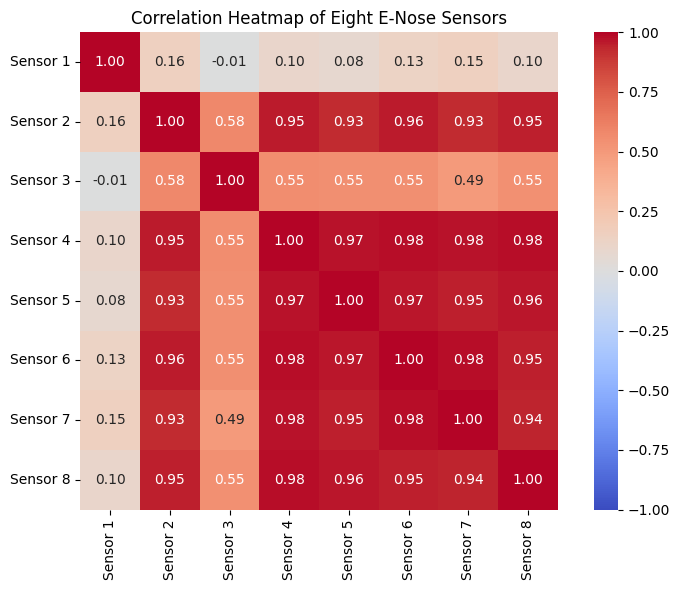

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sensor column names
sensor_names = [f"Sensor {i}" for i in range(1, 9)]

# Combine all measurements
all_data = []

for quality, samples in measurements.items():
    for sample_name, signal in samples.items():

        df = pd.DataFrame(signal, columns=sensor_names)
        df["Quality"] = quality
        df["Measurement"] = sample_name

        all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

# Calculate correlation between sensor channels
correlation_matrix = combined_df[sensor_names].corr()

# Plot heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of Eight E-Nose Sensors")
plt.tight_layout()
plt.show()

In [33]:
correlation_matrix.to_csv("sensor_correlation_matrix.csv")

print("Sensor correlation matrix:")
display(correlation_matrix.round(3))

print("Saved as sensor_correlation_matrix.csv")

Sensor correlation matrix:


,Sensor 1,Sensor 2,Sensor 3,Sensor 4,Sensor 5,Sensor 6,Sensor 7,Sensor 8
Sensor 1,1.000,0.156,-0.007,0.101,0.077,0.126,0.153,0.099
Sensor 2,0.156,1.000,0.584,0.954,0.929,0.959,0.929,0.952
Sensor 3,-0.007,0.584,1.000,0.555,0.549,0.554,0.495,0.545
Sensor 4,0.101,0.954,0.555,1.000,0.974,0.977,0.976,0.979
Sensor 5,0.077,0.929,0.549,0.974,1.000,0.967,0.947,0.961
Sensor 6,0.126,0.959,0.554,0.977,0.967,1.000,0.982,0.949
Sensor 7,0.153,0.929,0.495,0.976,0.947,0.982,1.000,0.938
Sensor 8,0.099,0.952,0.545,0.979,0.961,0.949,0.938,1.000


Saved as sensor_correlation_matrix.csv


# Conclusion: Sensor Correlation Analysis

- Sensors 2, 4, 5, 6, 7, and 8 exhibit **strong positive correlations** (approximately 0.93–0.98), indicating similar overall variations across the pooled observations.
- Sensor 3 shows moderate correlations with most of these sensors (approximately 0.49–0.58).
- Sensor 1 has weak correlations with all other sensors (approximately −0.15 to 0.16), suggesting it captures a different pattern.
- No strong negative correlations are observed.

**Overall:** The sensors exhibit different levels of correlation. Our Transformer should learn both individual sensor dynamics and relationships between sensors to generate realistic multivariate time-series data. Note that these correlations pool all time steps and measurements, so they may reflect shared temporal trends as well as sensor relationships.**